# 02 · Evaluation metrics: object detection

**Goal:** understand how an object detector is evaluated, from IoU to mAP, by computing each step **by hand** on a small scene.

**Use case:** a camera that must **find every person** in an image (as in people counting or pedestrian detection). For each person, the model draws a **box** and gives a **confidence score**.

**The evaluation chain:**
**IoU** grades each box → **TP / FP / FN** → **precision & recall** → **AP** (one score over all thresholds) → **mAP** (average over classes)

**Contents:** 1. The scene · 2. Box IoU · 3. Matching · 4. Precision and recall · 5. AP · 6. mAP · 7. Summary

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from metrics import box_iou, match_predictions, average_precision, ap_over_iou_thresholds, precision, recall

os.makedirs("figures", exist_ok=True)
plt.rcParams["figure.dpi"] = 100

---
## 1. The scene

A tiny 30 × 30 pixel street scene with **3 people**. The ground truth is one box per person, drawn by a human, written as `(x_min, y_min, x_max, y_max)`.

The model outputs **5 boxes**, each with a confidence score:
- **A** (0.95): well placed on person 1
- **B** (0.88): well placed on person 3 (a bit too wide)
- **C** (0.70): badly placed near person 2
- **D** (0.45): in the sky, on nothing
- **E** (0.30): well placed on person 2, but with low confidence

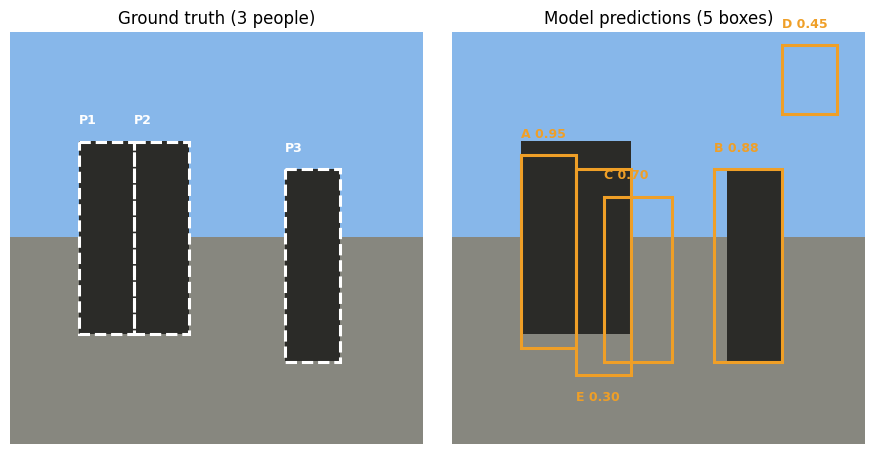

In [2]:
H, W = 30, 30
# Ground truth: one box per person
gt_boxes = [(5, 8, 9, 22),     # person 1
            (9, 8, 13, 22),    # person 2 (touching person 1)
            (20, 10, 24, 24)]  # person 3

# Model predictions: (box, confidence score)
pred_boxes = [((5, 9, 9, 23),    0.95),   # A
              ((19, 10, 24, 24), 0.88),   # B
              ((11, 12, 16, 24), 0.70),   # C
              ((24, 1, 28, 6),   0.45),   # D
              ((9, 10, 13, 25),  0.30)]   # E
NAMES = "ABCDE"

# A simple "photo": sky, road, and the 3 people
photo = np.zeros((H, W, 3))
photo[:15] = [0.53, 0.72, 0.92]; photo[15:] = [0.53, 0.53, 0.50]
for x1, y1, x2, y2 in gt_boxes:
    photo[y1:y2, x1:x2] = [0.17, 0.17, 0.16]

def draw_box(ax, box, color, label=None, ls="-", below=False):
    x1, y1, x2, y2 = box
    ax.add_patch(Rectangle((x1 - 0.5, y1 - 0.5), x2 - x1, y2 - y1, fill=False, edgecolor=color, lw=2.2, ls=ls))
    if label:
        y_text = y2 + 1.3 if below else y1 - 1.8   # label under the box if asked, to avoid overlaps
        ax.text(x1 - 0.5, y_text, label, color=color, fontsize=9, fontweight="bold")

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
axes[0].imshow(photo)
for i, b in enumerate(gt_boxes, start=1):
    draw_box(axes[0], b, "white", f"P{i}", ls="--")
axes[0].set_title("Ground truth (3 people)"); axes[0].axis("off")
axes[1].imshow(photo)
for (b, s), n in zip(pred_boxes, NAMES):
    draw_box(axes[1], b, "#EF9F27", f"{n} {s:.2f}", below=(n == "E"))
axes[1].set_title("Model predictions (5 boxes)"); axes[1].axis("off")
plt.tight_layout()
plt.savefig("figures/02_scene.png", dpi=150, bbox_inches="tight")
plt.show()

---
## 2. Box IoU

**The idea:** how well does a predicted box cover a real object?

$$\text{IoU} = \frac{\text{area of overlap}}{\text{area of union}}$$

1 = perfect match, 0 = no overlap. The same idea as mask IoU in segmentation, applied to rectangles.

In [3]:
gt_b = gt_boxes[0]
for name, pred_b in [("same box", gt_b), ("shifted 1 px right+down", (6, 9, 10, 23)),
                     ("shifted 3 px right+down", (8, 11, 12, 25)), ("far away", (20, 1, 24, 6))]:
    print(f"{name:<25} IoU = {box_iou(gt_b, pred_b):.2f}")

same box                  IoU = 1.00
shifted 1 px right+down   IoU = 0.53
shifted 3 px right+down   IoU = 0.11
far away                  IoU = 0.00


---
## 3. Matching: is each box correct?

**The rule:** a box is correct if its IoU with a real object is **≥ 0.5**.
- **TP**: correct box. **FP**: badly placed box or false alarm. **FN**: real object that no box found.
- Boxes are processed **from most to least confident**, and each real object can be matched **only once** (a duplicate = FP).
- ⚠️ **There is no TN in detection**: "every empty place where the model correctly drew nothing" cannot be counted.

**Confidence vs. IoU:** confidence is the model's **own opinion**, given before any check. IoU is **our check** against the ground truth. They are independent: a box can be confident and wrong, or hesitant and right.

Box   Confidence  Best IoU   Result
A           0.95      0.87   TP (person 1)
B           0.88      0.80   TP (person 3)
C           0.70      0.21   FP
D           0.45      0.00   FP
E           0.30      0.71   TP (person 2)


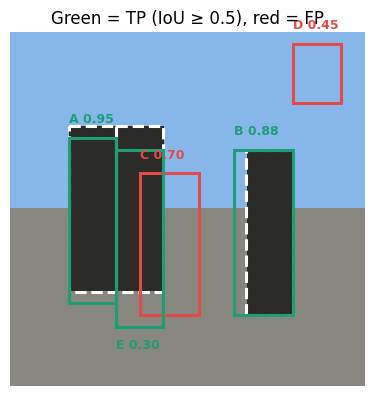

In [4]:
rows = match_predictions(pred_boxes, gt_boxes, box_iou, iou_threshold=0.5)

print(f"{'Box':<5}{'Confidence':>11}{'Best IoU':>10}   Result")
for r in rows:
    res = f"TP (person {r['gt'] + 1})" if r["correct"] else "FP"
    print(f"{NAMES[r['index']]:<5}{r['score']:>11.2f}{r['iou']:>10.2f}   {res}")

fig, ax = plt.subplots(figsize=(4.6, 4.6))
ax.imshow(photo)
for b in gt_boxes:
    draw_box(ax, b, "white", ls="--")
for r in rows:
    b, s = pred_boxes[r["index"]]
    draw_box(ax, b, "#1D9E75" if r["correct"] else "#E24B4A", f"{NAMES[r['index']]} {s:.2f}", below=(NAMES[r["index"]] == "E"))
ax.set_title("Green = TP (IoU ≥ 0.5), red = FP"); ax.axis("off")
plt.savefig("figures/02_matching.png", dpi=150, bbox_inches="tight")
plt.show()

Box **C** was fairly confident (0.70) but **wrong**. Box **E** was hesitant (0.30) but **right**.

---
## 4. Precision and recall

- **Precision** = TP / (TP + FP) → of the boxes drawn, how many are correct?
- **Recall** = TP / number of real objects → of the real people, how many were found?

In practice, we keep only boxes above a **confidence threshold**, exactly like the threshold in binary classification. Changing it changes the results:

In [5]:
n_gt = len(gt_boxes)
print(f"{'Threshold':<11}{'Boxes kept':<14}{'TP':>4}{'FP':>4}{'Precision':>11}{'Recall':>8}")
for t in [0.9, 0.8, 0.6, 0.4, 0.2]:
    kept = [r for r in rows if r["score"] >= t]
    tp = sum(r["correct"] for r in kept); fp = len(kept) - tp
    print(f"{t:<11}{', '.join(NAMES[r['index']] for r in kept):<14}{tp:>4}{fp:>4}{precision(tp, fp):>11.2f}{tp / n_gt:>8.2f}")

Threshold  Boxes kept      TP  FP  Precision  Recall
0.9        A                1   0       1.00    0.33
0.8        A, B             2   0       1.00    0.67
0.6        A, B, C          2   1       0.67    0.67
0.4        A, B, C, D       2   2       0.50    0.67
0.2        A, B, C, D, E    3   2       0.60    1.00


Strict threshold → few boxes, all correct, but people are missed. Loose threshold → everyone found, plus false alarms. To get **one score that doesn't depend on the threshold**, we use AP.

---
## 5. AP (Average Precision)

**The recipe (ranked-list method):**
1. Sort the boxes by confidence (this is **the only job of confidence**).
2. Read the list from top to bottom. At each **correct** box, write down: **correct so far ÷ read so far**.
3. Every real object **never found** gets **0**.
4. **AP = the average of these values** (one value per real object).

**What AP checks:** did the model **find all the objects**, and did it put its **correct boxes at the top** of its confidence ranking?

In [6]:
correct_so_far = 0
print(f"{'Read':<6}{'Box':<5}{'Correct?':<10}{'Correct so far':>15}{'Read so far':>13}   Write down")
for k, r in enumerate(rows, start=1):
    correct_so_far += r["correct"]
    note = f"{correct_so_far}/{k} = {correct_so_far / k:.2f}" if r["correct"] else "-"
    print(f"{k:<6}{NAMES[r['index']]:<5}{'yes' if r['correct'] else 'no':<10}{correct_so_far:>15}{k:>13}   {note}")

print(f"\nAP = (1.00 + 1.00 + 0.60) / 3 = {average_precision(rows, n_gt):.2f}")

Read  Box  Correct?   Correct so far  Read so far   Write down
1     A    yes                     1            1   1/1 = 1.00
2     B    yes                     2            2   2/2 = 1.00
3     C    no                      2            3   -
4     D    no                      2            4   -
5     E    yes                     3            5   3/5 = 0.60

AP = (1.00 + 1.00 + 0.60) / 3 = 0.87


### Same boxes, different order

What happens if the model ranks the **same 5 boxes** differently? We keep the boxes and only change the confidence scores.

In [7]:
def reorder(order):
    # Give decreasing scores following the chosen order of box names
    scores = {n: 1 - 0.1 * i for i, n in enumerate(order)}
    return [(b, scores[n]) for (b, _), n in zip(pred_boxes, NAMES)]

print(f"{'Ranking':<26}{'AP (simple)':>12}{'AP (official*)':>16}")
for label, order in [("Our model: A B C D E", "ABCDE"),
                     ("Correct first: A B E C D", "ABECD"),
                     ("Wrong first: C D A B E", "CDABE")]:
    rws = match_predictions(reorder(order), gt_boxes, box_iou, 0.5)
    print(f"{label:<26}{average_precision(rws, n_gt):>12.2f}{average_precision(rws, n_gt, interpolated=True):>16.2f}")

Ranking                    AP (simple)  AP (official*)
Our model: A B C D E              0.87            0.87
Correct first: A B E C D          1.00            1.00
Wrong first: C D A B E            0.48            0.60


**Same boxes, same objects found, very different AP.** A good detector is **most confident about its correct boxes**: it "knows when it's right".

\* *Official benchmarks (Pascal VOC, COCO) add a smoothing rule: each written value is replaced by the best precision reached further down the list. The values can differ slightly, but the lesson is the same.*

---
## 6. mAP (mean Average Precision)

**mAP = the average of AP over all classes** (person, car, dog…). Every class gets an equal vote, like a macro average. For example, AP(person) = 0.87, AP(car) = 0.70, AP(dog) = 0.45 → mAP = 0.67.

**How strict is "correct"?** Think of teachers grading the boxes:
- **mAP@0.5** (Pascal VOC): one **lenient** teacher, a box is correct if IoU ≥ 0.5. → "Did you find the objects?"
- **mAP@[0.5:0.95]** (COCO): a **panel of 10 teachers**, from lenient (0.50) to very strict (0.95), and we average their grades. → "Did you find them **and** place the boxes precisely?"

IoU ≥ 0.50 -> AP = 0.87
IoU ≥ 0.55 -> AP = 0.87
IoU ≥ 0.60 -> AP = 0.87
IoU ≥ 0.65 -> AP = 0.87
IoU ≥ 0.70 -> AP = 0.87
IoU ≥ 0.75 -> AP = 0.67
IoU ≥ 0.80 -> AP = 0.67
IoU ≥ 0.85 -> AP = 0.33
IoU ≥ 0.90 -> AP = 0.00
IoU ≥ 0.95 -> AP = 0.00

mAP@0.5        (Pascal VOC) = 0.87
mAP@[0.5:0.95] (COCO)       = 0.60


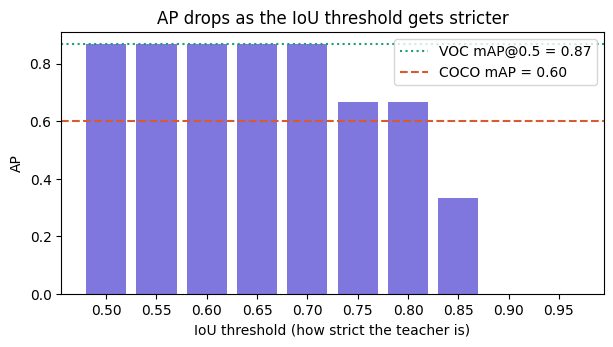

In [8]:
thresholds, aps = ap_over_iou_thresholds(pred_boxes, gt_boxes, box_iou)
for t, a in zip(thresholds, aps):
    print(f"IoU ≥ {t:.2f} -> AP = {a:.2f}")
print(f"\nmAP@0.5        (Pascal VOC) = {aps[0]:.2f}")
print(f"mAP@[0.5:0.95] (COCO)       = {np.mean(aps):.2f}")

plt.figure(figsize=(7, 3.4))
plt.bar([f"{t:.2f}" for t in thresholds], aps, color="#7F77DD")
plt.axhline(aps[0], color="#1D9E75", ls=":", label=f"VOC mAP@0.5 = {aps[0]:.2f}")
plt.axhline(np.mean(aps), color="#D85A30", ls="--", label=f"COCO mAP = {np.mean(aps):.2f}")
plt.xlabel("IoU threshold (how strict the teacher is)"); plt.ylabel("AP")
plt.title("AP drops as the IoU threshold gets stricter"); plt.legend()
plt.savefig("figures/02_map_voc_vs_coco.png", dpi=150, bbox_inches="tight")
plt.show()

Our model **finds** the people (lenient teacher: 0.87), but its boxes are only **roughly placed** (IoU 0.71 to 0.87), so the strict teachers fail them and COCO's average drops to 0.60. **COCO rewards precise localization.**

---
## 7. Summary

| Step | What it does | Our example |
|---|---|---|
| **Box IoU** | Measures how well a box covers a real object | A: 0.87, C: 0.21 |
| **Matching** | IoU ≥ 0.5 → TP, otherwise FP; objects never found → FN | 3 TP, 2 FP, 0 FN |
| **Precision / recall** | Depend on the confidence threshold | 0.60 / 1.00 with all boxes |
| **AP** | Ranked list: finds everything + correct boxes on top? | 0.87 |
| **mAP** | Average over classes (and IoU thresholds for COCO) | VOC 0.87, COCO 0.60 |

> **Key takeaway:** IoU grades each box, confidence ranks the boxes, AP rewards models that find every object and are confident about the right boxes, and COCO's mAP also demands precise boxes.